In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

df_sales = pd.read_csv('../data/processed/cleaned_retail_sales.csv')
print(df_sales.shape)
df_sales.head()

(10000, 30)


,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Name,Segment,Region,Product_ID,Product_Category,Product_Sub_Category,...,Profit_Capped,Year,Month,Quarter,Day_of_Week,Is_Weekend,Delivery_Days,Profit_Margin_Pct,Profit_Margin_Pct_Capped,Profit_Margin_Pct_Final
0,ORD000001,2022-01-01 00:00:00,2022-01-02 00:00:00,CUST1127,Customer_1275,Consumer,Central,PROD0215,Office Supplies,Appliances,...,39.775401,2022,1,1,5,1,1,16.859239,16.859239,16.859239
1,ORD000002,2022-01-01 01:00:00,2022-01-02 01:00:00,CUST1460,Customer_1334,Corporate,East,PROD0002,Furniture,Shirts,...,12.835350,2022,1,1,5,1,1,7.110889,7.110889,7.110889
2,ORD000003,2022-01-01 02:00:00,2022-01-02 02:00:00,CUST0861,Customer_1744,Corporate,East,PROD0121,Electronics,Paper,...,46.203636,2022,1,1,5,1,1,112.755054,112.755054,112.755054
3,ORD000004,2022-01-01 03:00:00,2022-01-02 03:00:00,CUST1295,Customer_833,Corporate,East,PROD0103,Clothing,Appliances,...,14.270852,2022,1,1,5,1,1,3.384399,5.183136,5.183136
4,ORD000005,2022-01-01 04:00:00,2022-01-02 04:00:00,CUST1131,Customer_140,Consumer,South,PROD0149,Office Supplies,Accessories,...,-61.865679,2022,1,1,5,1,1,-41.275049,-40.717661,-40.717661


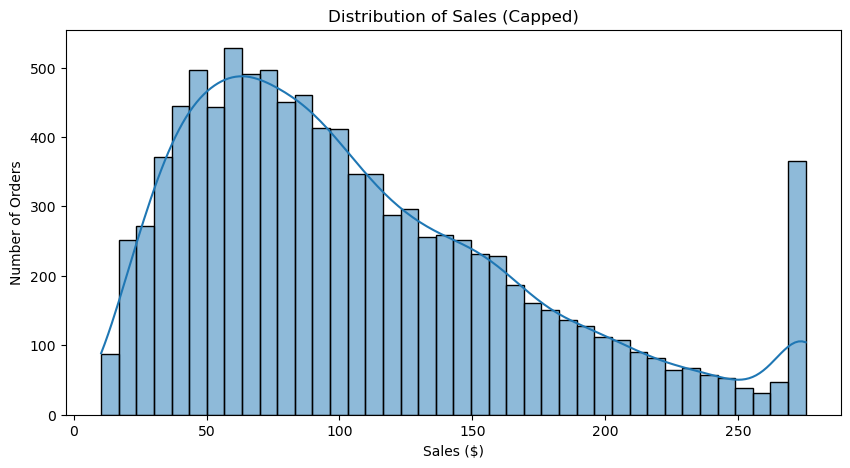

In [2]:
plt.figure(figsize=(10, 5))
sns.histplot(df_sales['Sales_Capped'], bins=40, kde=True)
plt.title('Distribution of Sales (Capped)')
plt.xlabel('Sales ($)')
plt.ylabel('Number of Orders')
plt.show()

Product_Category
Electronics        328422.713112
Office Supplies    321280.864068
Furniture          214958.032671
Clothing           214009.369624
Name: Sales_Capped, dtype: float64


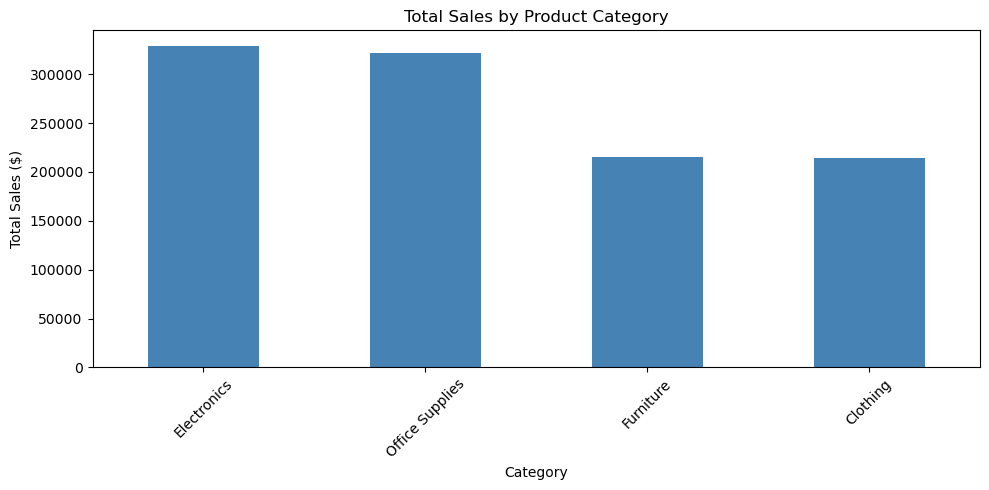

In [3]:
category_sales = df_sales.groupby('Product_Category')['Sales_Capped'].sum().sort_values(ascending=False)
print(category_sales)

plt.figure(figsize=(10, 5))
category_sales.plot(kind='bar', color='steelblue')
plt.title('Total Sales by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

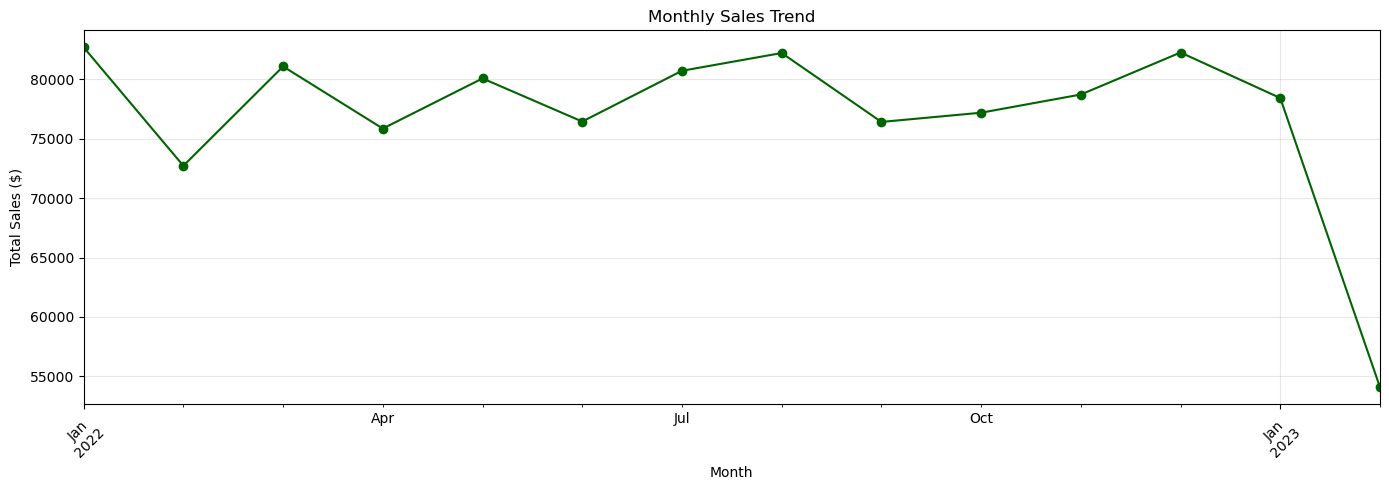

In [4]:
df_sales['Order_Date'] = pd.to_datetime(df_sales['Order_Date'])
monthly_sales = df_sales.groupby(df_sales['Order_Date'].dt.to_period('M'))['Sales_Capped'].sum()

plt.figure(figsize=(14, 5))
monthly_sales.plot(kind='line', marker='o', color='darkgreen')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
print(df_sales['Order_Date'].max())
print(df_sales['Order_Date'].min())

2023-02-21 15:00:00
2022-01-01 00:00:00


In [6]:
# ============================================================
# STEP 31: TOP PRODUCTS & PARETO ANALYSIS (80/20 RULE)
# ============================================================

top_products = df_sales.groupby('Product_Name')['Sales_Capped'].sum().sort_values(ascending=False)

top_20pct_count = int(len(top_products) * 0.2)
top_20pct_revenue = top_products.head(top_20pct_count).sum()
total_revenue = top_products.sum()
pareto_pct = (top_20pct_revenue / total_revenue) * 100

print("Total unique products:", len(top_products))
print("Top 10 products by sales:")
print(top_products.head(10))
print()
print(f"Top 20% of products ({top_20pct_count} products) generate {pareto_pct:.1f}% of total revenue")

Total unique products: 499
Top 10 products by sales:
Product_Name
Product_291    3970.096267
Product_2      3704.929597
Product_337    3663.076070
Product_69     3628.408737
Product_154    3592.281130
Product_54     3590.611272
Product_180    3513.526141
Product_387    3495.875330
Product_289    3482.533312
Product_300    3452.769205
Name: Sales_Capped, dtype: float64

Top 20% of products (99 products) generate 27.2% of total revenue


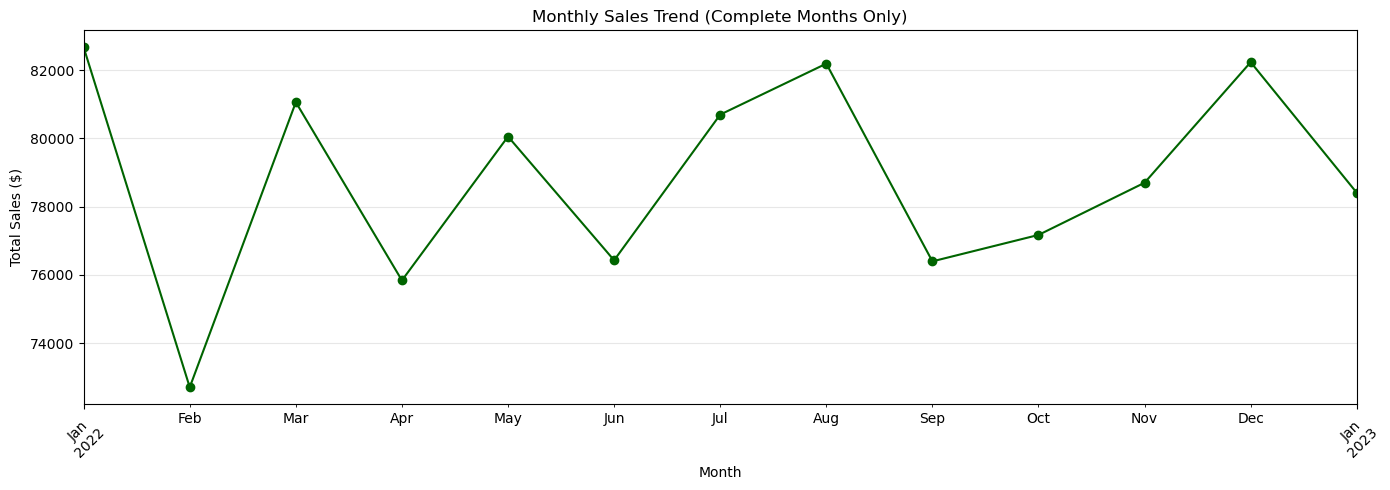

Excluded partial month: Feb 2023 (only 21 days of data)
Average monthly sales (complete months): 78813.92148783468
Min: 72709.32910555991 | Max: 82670.48146322479


In [7]:
# ============================================================
# STEP 32: HANDLING THE INCOMPLETE FINAL MONTH
# ============================================================

monthly_sales_full = monthly_sales[monthly_sales.index < pd.Period('2023-02', freq='M')]

plt.figure(figsize=(14, 5))
monthly_sales_full.plot(kind='line', marker='o', color='darkgreen')
plt.title('Monthly Sales Trend (Complete Months Only)')
plt.xlabel('Month')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Excluded partial month: Feb 2023 (only 21 days of data)")
print("Average monthly sales (complete months):", monthly_sales_full.mean())
print("Min:", monthly_sales_full.min(), "| Max:", monthly_sales_full.max())

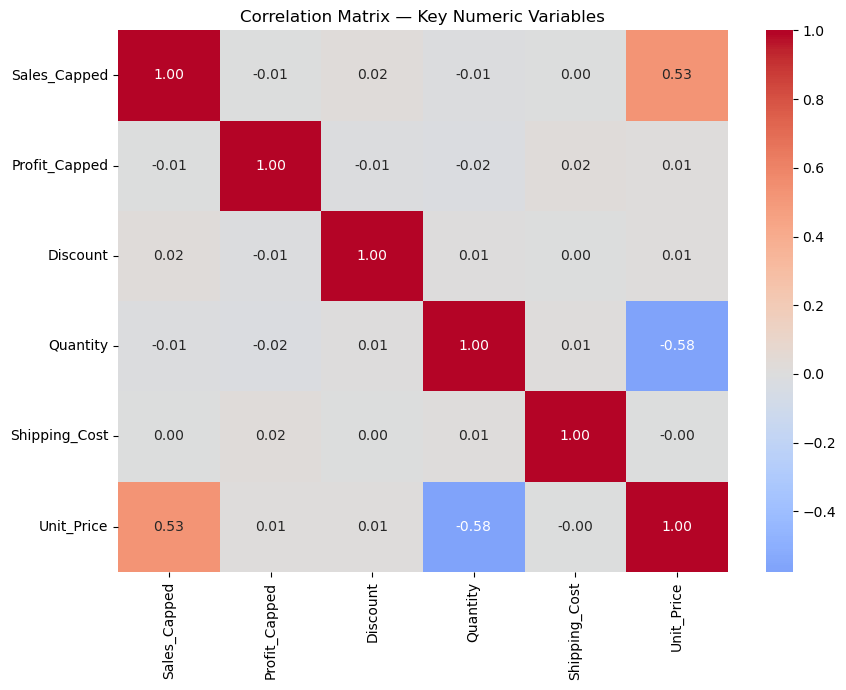

Sales_Capped     1.000000
Unit_Price       0.530535
Discount         0.019058
Shipping_Cost    0.001238
Profit_Capped   -0.005396
Quantity        -0.010920
Name: Sales_Capped, dtype: float64


In [8]:
# ============================================================
# CORRELATION ANALYSIS
# ============================================================

corr_cols = ['Sales_Capped', 'Profit_Capped', 'Discount', 'Quantity', 'Shipping_Cost', 'Unit_Price']
corr_matrix = df_sales[corr_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation Matrix — Key Numeric Variables')
plt.tight_layout()
plt.show()

print(corr_matrix['Sales_Capped'].sort_values(ascending=False))

In [9]:
# ============================================================
# EDA KEY FINDINGS SUMMARY
# ============================================================

findings = """
RETAIL SALES — EDA KEY FINDINGS
================================
1. Sales are right-skewed: most orders are modest, a smaller number are large (median well below mean before capping).
2. Electronics ($328K) and Office Supplies ($321K) form a top revenue tier; Furniture and Clothing trail ~35% lower.
3. No Pareto concentration: top 20% of products (99 of 499) generate only 27.2% of revenue -- revenue is broadly distributed, not hit-driven.
4. Monthly sales are stable (complete months: $72.7K-$82.7K, avg $78.8K) with no dominant seasonal pattern or clear growth trend.
5. Discount shows no meaningful correlation with Sales or Profit (~0.00-0.02) -- discounting is not currently a lever tied to either outcome.
6. Unit Price and Quantity are moderately negatively correlated (-0.58): customers buy more units of cheaper items, fewer of expensive ones.
"""

print(findings)

with open('../outputs/reports/03_eda_key_findings.txt', 'w') as f:
    f.write(findings)

print("Saved to outputs/reports/03_eda_key_findings.txt")


RETAIL SALES — EDA KEY FINDINGS
1. Sales are right-skewed: most orders are modest, a smaller number are large (median well below mean before capping).
2. Electronics ($328K) and Office Supplies ($321K) form a top revenue tier; Furniture and Clothing trail ~35% lower.
3. No Pareto concentration: top 20% of products (99 of 499) generate only 27.2% of revenue -- revenue is broadly distributed, not hit-driven.
4. Monthly sales are stable (complete months: $72.7K-$82.7K, avg $78.8K) with no dominant seasonal pattern or clear growth trend.
5. Discount shows no meaningful correlation with Sales or Profit (~0.00-0.02) -- discounting is not currently a lever tied to either outcome.
6. Unit Price and Quantity are moderately negatively correlated (-0.58): customers buy more units of cheaper items, fewer of expensive ones.

Saved to outputs/reports/03_eda_key_findings.txt
